<!-- DRAFT: Graeme to edit -->
# Day 2 · 10 (full data) — Lab: model selection, ensembles and final standings (20 min)

Every notebook saved its test forecasts for the 2,000 evaluation series. Here we put them
side by side, with the selected model (`gd.selected_config()`: 05 or 05b) as the incumbent,
and ask better questions than "which has the lowest RMSSE?".

Goals

1. **Win rates**: on what share of series does model A beat model B?
2. **Bradley–Terry and Elo**: one strength number per model from every series-level duel.
3. **Ties**: which models are within the seed noise (notebook 02) of the best?
4. **Ensembles**: mean, median, top 3 and per-class selection, chosen on half the series.
5. **Final standings**, with accuracy **and** price response side by side.

**In the chain:** reads the selected config, `00_baselines`, `02_shortlist`, `04_price`,
`05_selected` and `05b_synthetic`, writes `10_final`.

<!-- DRAFT: Graeme to edit -->
## Intuition: a league table for models

![Rating difference against win chance](../slides/img/elo_curve.png)

Treat every series as a match between two models: the one with the lower RMSSE wins. The
**win rate** ignores the margin, so one disaster cannot dominate. **Bradley–Terry** and
**Elo** turn all the matches into one rating, as in chess: +100 points is about a 64% chance
of winning a series. Two models whose medians differ by less than the seed noise are
**tied**: retraining with a different seed could swap them.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import gd_helpers as gd
import gd_plots as gplt
import gd_price as gp

bc = gd.bc
gd.status()
gplt.use_style()

/home/gdavidson/code/time-series-forecasting-bootcamp/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


LOAD (read saved results) | results: results/day2_full | accelerator: gpu


<!-- DRAFT: Graeme to edit -->
## 1. Every saved forecast, on the evaluation series

Models that forecast only a subset of the series (e.g. a foundation model run on a CPU) are
left out: a fair standing needs every model on the same series. As in 06–09, the selected
model is the column `GFM_selected`. If 05b won, 05's own model stays in as `GFM_05`. The
table lists each model's median RMSSE.

In [2]:
panel = gd.train_panel()
train, test = bc.split(panel, cutoff=bc.TEST_START)
info = gplt.series_table(panel)
eval_ids = gd.eval_ids()

selected_cfg = gd.selected_config()
selected_col = "GFM_selected"
synthetic_won = selected_cfg.get("use") == "05b"

fc = gd.only(bc.load_forecasts(), eval_ids)
earlier_run = [c for c in fc.columns if c.startswith(("ENS_", "SEL_"))]
fc = fc.drop(columns=earlier_run)
if synthetic_won:            # 05b's column becomes GFM_selected; 05's is kept as GFM_05
    fc = fc.drop(columns=selected_cfg["forecast_column"])
    fc = fc.rename(columns={"GFM_selected": "GFM_05"})
    fc = fc.merge(gd.selected_forecasts(selected_cfg), on=["unique_id", "ds"], how="left")
all_models = bc.model_columns(fc)
coverage = fc.groupby("unique_id")[all_models].apply(lambda g: g.notna().all()).sum()
coverage = coverage / len(eval_ids)
models = list(coverage[coverage >= 0.99].index)
left_out = coverage[coverage < 0.99].round(3)
if len(left_out):
    print("left out (forecast only a share of the series):", left_out.to_dict())
fc = fc[["unique_id", "ds"] + models].dropna(subset=models, how="any")
print(f"{len(models)} models on {fc['unique_id'].nunique():,} series: {models}")

24 models on 1,997 series: ['Naive', 'SeasonalNaive', 'AutoETS', 'LightGBM', 'NBEATSx_off_mean', 'NBEATSx_recipe_mean', 'NHITS_recipe_mean', 'NBEATSx_tuned', 'NBEATSx_cal_hier', 'NBEATSx_A_features_mean', 'NBEATSx_B_cpi_mean', 'NBEATSx_C_cpi_over_mean', 'GFM_selected', 'GFM_synthetic', 'GFM_cluster_static', 'GFM_per_cluster', 'Chronos2_zs', 'Chronos2_zs_cov', 'GFM_BottomUp', 'GFM_TopDown', 'GFM_MiddleOut', 'GFM_MinT-ols', 'GFM_MinT-wls_struct', 'GFM_quantile']


In [3]:
metrics = gd.score(fc, test, train)
R = gd.per_series(metrics)[models].dropna()
R.median().sort_values().round(3)

Chronos2_zs_cov            0.512
NHITS_recipe_mean          0.537
NBEATSx_B_cpi_mean         0.540
GFM_synthetic              0.543
GFM_selected               0.546
GFM_cluster_static         0.550
GFM_BottomUp               0.552
NBEATSx_C_cpi_over_mean    0.553
NBEATSx_A_features_mean    0.568
NBEATSx_recipe_mean        0.568
NBEATSx_tuned              0.568
LightGBM                   0.568
GFM_per_cluster            0.569
GFM_quantile               0.592
GFM_MiddleOut              0.639
GFM_TopDown                0.642
Chronos2_zs                0.645
NBEATSx_cal_hier           0.646
GFM_MinT-wls_struct        0.700
AutoETS                    0.707
Naive                      0.770
NBEATSx_off_mean           0.771
GFM_MinT-ols               0.803
SeasonalNaive              0.929
dtype: float64

<!-- DRAFT: Graeme to edit -->
## 2. Pairwise win rates

The win matrix: cell (row A, column B) is the share of series where A has the lower RMSSE.
Ties (e.g. two models that both forecast zero) count half. Rows are sorted by average win
rate, so the strongest model is at the top. Blue cells (above 0.5) are wins for the row, red
cells losses; pale cells near 0.5 are coin flips.

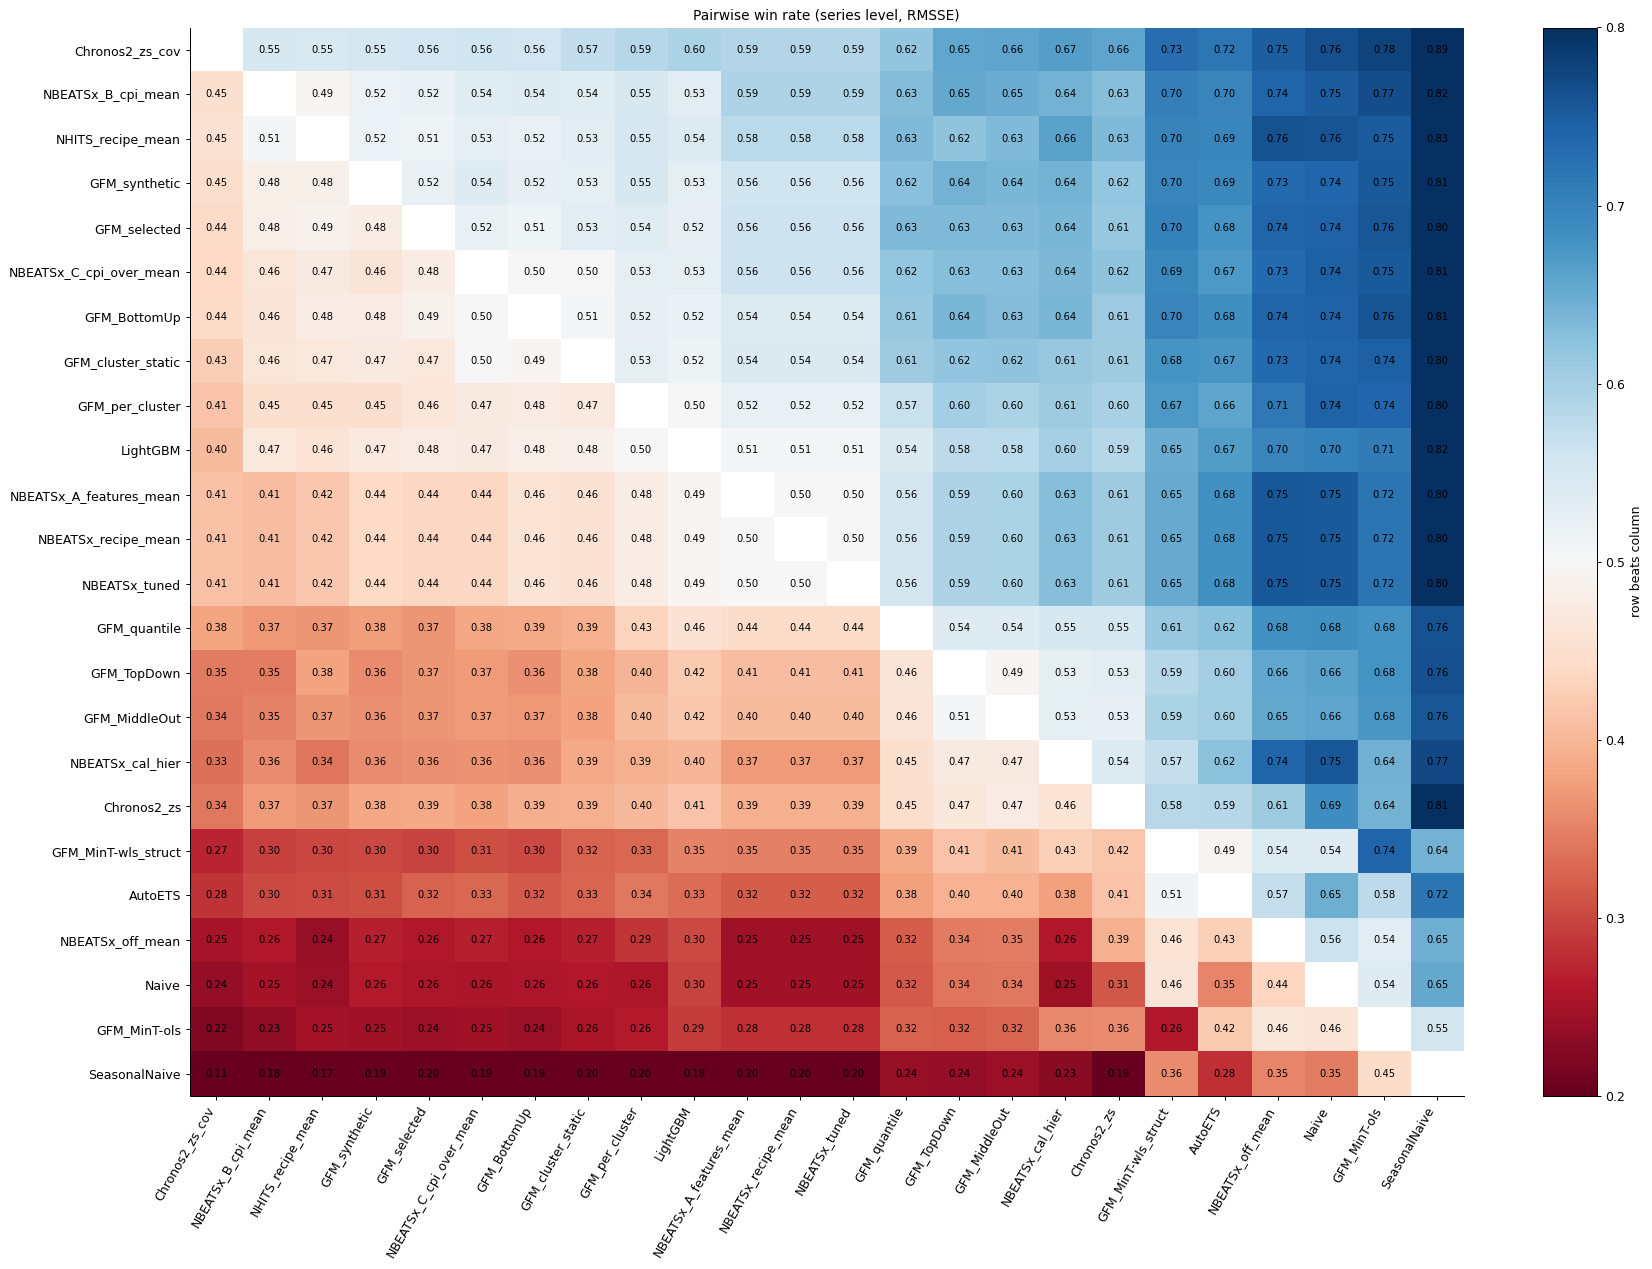

In [4]:
def win_matrix(R: pd.DataFrame) -> pd.DataFrame:
    """Share of series on which each row model beats each column model (ties count half)."""
    a = R.to_numpy()
    ties = (a[:, :, None] == a[:, None, :]).mean(0)
    wins = (a[:, :, None] < a[:, None, :]).mean(0) + 0.5 * ties
    np.fill_diagonal(wins, np.nan)
    return pd.DataFrame(wins, index=R.columns, columns=R.columns)


W = win_matrix(R)
order = W.mean(axis=1).sort_values(ascending=False).index
W = W.loc[order, order]
gplt.plot_heatmap(W, "Pairwise win rate (series level, RMSSE)", cmap="RdBu",
                  label="row beats column", vmin=0.2, vmax=0.8, xrotation=60,
                  figsize=(2 + 0.75 * len(order), 1 + 0.55 * len(order)))

<!-- DRAFT: Graeme to edit -->
## 3. Bradley–Terry and Elo

Both turn the win matrix into one rating per model, on a scale where 1000 is average.

* **Bradley–Terry**: P(A beats B) = s_A / (s_A + s_B), fitted by maximum likelihood on every
  pairwise result (the classic MM algorithm).
* **Elo**: replay the series in a random order and update the ratings after each one. The
  order matters, so we average over shuffles. All duels of one series are scored at once,
  which keeps the replay fast on 2,000 series.

In [5]:
def bradley_terry(R: pd.DataFrame, iters: int = 500) -> pd.Series:
    """Bradley–Terry strengths on an Elo-like scale (1000 = average)."""
    a = R.to_numpy()
    ties = (a[:, :, None] == a[:, None, :]).sum(0)
    wins = (a[:, :, None] < a[:, None, :]).sum(0) + 0.5 * ties
    np.fill_diagonal(wins, 0)
    games = wins + wins.T
    s = np.ones(a.shape[1])
    for _ in range(iters):
        s_new = wins.sum(1) / (games / (s[:, None] + s[None, :])).sum(1)
        s_new = s_new / np.exp(np.log(s_new).mean())
        if np.allclose(s, s_new, rtol=1e-10):
            break
        s = s_new
    return pd.Series(400 * np.log10(s) + 1000, index=R.columns, name="bradley_terry")


def elo(R: pd.DataFrame, k: float = 4.0, n_shuffles: int = 10, seed: int = 0) -> pd.Series:
    """Elo ratings from replaying the series in random orders (all duels of a series at once)."""
    rng = np.random.default_rng(seed)
    a = R.to_numpy()
    total = np.zeros(a.shape[1])
    for _ in range(n_shuffles):
        r = np.full(a.shape[1], 1000.0)
        for row in a[rng.permutation(len(a))]:
            expected = 1 / (1 + 10 ** ((r[None, :] - r[:, None]) / 400))
            result = (row[:, None] < row[None, :]) + 0.5 * (row[:, None] == row[None, :])
            r = r + k * (result - expected).sum(axis=1)     # the diagonal is 0.5 - 0.5
        total += r
    return pd.Series(total / n_shuffles, index=R.columns, name="elo")


ratings = pd.concat([R.median().rename("median_rmsse"), R.mean().rename("mean_rmsse"),
                     W.mean(axis=1).rename("avg_win_rate"), bradley_terry(R), elo(R)], axis=1)
ratings = ratings.sort_values("median_rmsse")
ratings.round(3)

,median_rmsse,mean_rmsse,avg_win_rate,bradley_terry,elo
Chronos2_zs_cov,0.512,1.044,0.640,1101.640,1121.332
NHITS_recipe_mean,0.537,1.028,0.612,1080.816,1116.443
NBEATSx_B_cpi_mean,0.540,1.043,0.614,1082.608,1075.119
GFM_synthetic,0.543,1.738,0.603,1074.063,1099.210
GFM_selected,0.546,1.037,0.599,1071.279,1073.616
GFM_cluster_static,0.550,1.055,0.583,1059.571,1063.175
GFM_BottomUp,0.552,1.046,0.590,1065.230,1039.219
NBEATSx_C_cpi_over_mean,0.553,1.042,0.591,1065.363,1076.581
NBEATSx_A_features_mean,0.568,1.078,0.556,1040.635,1036.636
NBEATSx_recipe_mean,0.568,1.078,0.556,1040.635,1036.636


<!-- DRAFT: Graeme to edit -->
### Reading the result

* When the median order and the rating order disagree, one model wins **often by a little**
  and the other **rarely by a lot**.
* The mean is pulled by the hardest (mostly intermittent) series; the median and the ratings
  count every series once. A model that ranks well on the median but poorly on the mean is
  strong on ordinary series and fragile on a few.
* Look at where `GFM_selected` sits: Bradley–Terry rating ≈ 1071 against LightGBM's ≈ 1043.

*Exact numbers vary with seed and hardware.*

<!-- DRAFT: Graeme to edit -->
## 4. Who is tied with the best?

Notebook 02 measured how much the median RMSSE moves when only the seed changes: the
**noise floor** (the incumbent's seed-to-seed standard deviation on validation). A model
within one noise floor of the best cannot be told apart from it. This is the
**equivalence band** drawn in the final chart.

In [6]:
shortlist_path = gd.CONFIG_DIR / "02_shortlist.json"
noise_floor = None
if shortlist_path.exists():
    noise_floor = gd.load_config("02_shortlist").get("noise_floor")
best_median = ratings["median_rmsse"].min()
if noise_floor is None:
    print("no 02 noise floor: only the best model counts as best")
    ratings["tied_with_best"] = ratings["median_rmsse"] == best_median
else:
    print(f"noise floor (02): {noise_floor:.4f} median RMSSE")
    ratings["tied_with_best"] = ratings["median_rmsse"] <= best_median + noise_floor
ratings[["median_rmsse", "mean_rmsse", "bradley_terry", "tied_with_best"]].round(3)

noise floor (02): 0.0048 median RMSSE


,median_rmsse,mean_rmsse,bradley_terry,tied_with_best
Chronos2_zs_cov,0.512,1.044,1101.640,True
NHITS_recipe_mean,0.537,1.028,1080.816,False
NBEATSx_B_cpi_mean,0.540,1.043,1082.608,False
GFM_synthetic,0.543,1.738,1074.063,False
GFM_selected,0.546,1.037,1071.279,False
GFM_cluster_static,0.550,1.055,1059.571,False
GFM_BottomUp,0.552,1.046,1065.230,False
NBEATSx_C_cpi_over_mean,0.553,1.042,1065.363,False
NBEATSx_A_features_mean,0.568,1.078,1040.635,False
NBEATSx_recipe_mean,0.568,1.078,1040.635,False


<!-- DRAFT: Graeme to edit -->
## 5. Ensembles

Choosing on the test window and then scoring on it is cheating. As in the original lab we
use a **cross-sectional split**: half the series choose which models go in, the other half
is scored. The choice uses the median RMSSE. We also add the research's pairing, the
selected GFM averaged with LightGBM: LightGBM was its most accurate model, N-BEATSx its best
on price response (§5, [100k set]).

In [7]:
rng = np.random.default_rng(bc.RANDOM_SEED)
ids = R.index.to_numpy()
sel_ids = set(rng.choice(ids, size=len(ids) // 2, replace=False))
R_sel = R[R.index.isin(sel_ids)]
top3 = list(R_sel.median().nsmallest(3).index)
by_class = R_sel.join(info["sale_class"]).groupby("sale_class")[models].median()
class_choice = by_class.idxmin(axis=1).to_dict()
print("top 3 on the selection half:", top3)
print("per-class choice:", class_choice)

clipped = fc[models].clip(lower=0)
ens = fc[["unique_id", "ds"]].copy()
ens["ENS_mean_all"] = clipped.mean(axis=1)
ens["ENS_median_all"] = clipped.median(axis=1)
ens["ENS_mean_top3"] = clipped[top3].mean(axis=1)
if selected_col in models and "LightGBM" in models:      # the research's pairing (§5)
    ens["ENS_gfm_lightgbm"] = clipped[[selected_col, "LightGBM"]].mean(axis=1)
cls = fc["unique_id"].map(info["sale_class"])
ens["SEL_by_class"] = clipped[top3[0]]
for sale_class, model in class_choice.items():
    ens.loc[cls == sale_class, "SEL_by_class"] = clipped.loc[cls == sale_class, model]
ens_models = bc.model_columns(ens)

top 3 on the selection half: ['Chronos2_zs_cov', 'GFM_synthetic', 'NHITS_recipe_mean']
per-class choice: {'A': 'GFM_MinT-ols', 'B': 'Chronos2_zs_cov', 'C': 'NBEATSx_recipe_mean', 'D': 'NHITS_recipe_mean', 'E': 'GFM_synthetic', 'F': 'NBEATSx_B_cpi_mean', 'G': 'Chronos2_zs_cov', 'H': 'Chronos2_zs_cov', 'I': 'Chronos2_zs_cov', 'J': 'Chronos2_zs_cov'}


/tmp/ipykernel_321051/2682199009.py:21: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[415765.79150648 413851.05737642 410287.05242412 412266.01549504
 415292.1225904  415706.12202332 411405.68536768 411927.45753922
 414268.09537118 411435.09741599 410676.66428255 408273.2968516
 413271.26506843 415749.10392987   9282.49056279   2942.76398045
   8051.15290246   1552.23994061   5546.29786803   2093.17214634
   8737.45688311   2536.57412455  10045.83829902   8491.0516727
  17998.63813399  19214.70402584  33732.29480239  36463.75348862
 266661.80196484 177712.09253566 174840.05895275 173134.78297763
 225111.8606325  282143.97720251 162339.15443375 159685.76735856
 234752.3202243  268122.48378023 158089.40483059 156428.03036395
 233084.15954954 268502.58743457  98203.89941001  16534.09338387
 100879.94257834  27876.37643377  82862.60393924  19168.85028348
  81834.88801598  16422.71211551  91059.66124771  170

In [8]:
both = fc.merge(ens, on=["unique_id", "ds"])
held_out = both[~both["unique_id"].isin(sel_ids)]
held_metrics = gd.score(held_out, test, train)
held_scores = bc.summarise(held_metrics, held_out, test)
held_scores = held_scores.sort_values("median_rmsse").reset_index(drop=True)
held_scores[["model", "median_rmsse", "mean_rmsse", "wape", "n_series"]].round(3).head(12)

,model,median_rmsse,mean_rmsse,wape,n_series
0,ENS_mean_top3,0.505,1.642,0.251,998
1,Chronos2_zs_cov,0.514,1.253,0.246,998
2,SEL_by_class,0.515,1.258,0.286,998
3,ENS_median_all,0.536,1.229,0.277,998
4,NHITS_recipe_mean,0.538,1.228,0.282,998
5,ENS_gfm_lightgbm,0.543,1.244,0.289,998
6,NBEATSx_B_cpi_mean,0.547,1.243,0.300,998
7,GFM_selected,0.550,1.236,0.292,998
8,GFM_cluster_static,0.552,1.258,0.304,998
9,GFM_BottomUp,0.555,1.245,0.291,998


<!-- DRAFT: Graeme to edit -->
### Reading the result

* Averaging lets the models' mistakes partly cancel. Does the top-3 average beat every
  single model on the held-out half, and by more than the noise floor (≈ 0.507 against
  Chronos-2's ≈ 0.514)? Yes, just: the gap of ≈ 0.007 is above the noise floor of ≈ 0.005.
* Per-class selection often fails to carry over to the held-out half. Selection overfits;
  averaging does not.
* The ensembles go on the board scored on **all** series, half of which chose them, so their
  board numbers are optimistic. Quote the held-out table.

*Exact numbers vary with seed and hardware.*

In [9]:
gd.save_forecasts(ens, "10_ensembles")
gd.record(ens, test, train, lab="10 ensembles",
          notes=f"top3={top3}; chosen on half the series (median RMSSE)")
gd.median_board()

,model,median_rmsse,mean_rmsse,wape,n_series,lab,fit_seconds
0,ENS_mean_top3,0.509,1.206,0.222,1996,10 ensembles,NaN
1,Chronos2_zs_cov,0.512,1.081,0.217,1999,07 foundation,2.960
2,SEL_by_class,0.516,1.049,0.238,1996,10 ensembles,NaN
3,ENS_gfm_lightgbm,0.533,1.031,0.254,1996,10 ensembles,NaN
4,ENS_median_all,0.535,1.023,0.246,1996,10 ensembles,NaN
5,NHITS_recipe_mean,0.539,1.063,0.251,1999,01 recipe (3-seed mean),249.433
6,NBEATSx_B_cpi_mean,0.540,1.076,0.263,1999,04 price arms (3-seed mean),522.767
7,GFM_synthetic,0.546,1.768,0.265,1999,05b synthetic (3-seed mean),361.200
8,GFM_selected,0.546,1.067,0.257,1999,05 selected (3-seed mean),379.767
9,GFM_cluster_static,0.551,1.086,0.268,1999,06 clusters (3-seed mean),367.433


<!-- DRAFT: Graeme to edit -->
## 6. Price response next to accuracy

An accurate model can still respond the wrong way to price. Notebooks 04, 05 and 05b report
the response with the same numbers every time: the median arc elasticity at ±20%, the share
of series that respond the wrong way (perverse), the share that are flat, and how many series
could be measured. This cell gathers those reports from the configs.

In [10]:
def find_reports(obj, path: str = "") -> list[dict]:
    """Every elasticity report (a dict with ``median_e20``) inside a config, with its path."""
    found = []
    if isinstance(obj, dict):
        if "median_e20" in obj and not isinstance(obj["median_e20"], dict):
            found.append({"path": path or "(top level)", **obj})
        for key, value in obj.items():
            if isinstance(value, dict):
                found += find_reports(value, f"{path}/{key}".strip("/"))
    return found


REPORT_COLS = ["median_e20", "share_perverse", "share_flat", "n_estimable", "invariance"]
reported = []
for name in ["04_price", "05_selected", "05b_synthetic"]:
    if (gd.CONFIG_DIR / f"{name}.json").exists():
        for rep in find_reports(gd.load_config(name)):
            reported.append({"config": name, **rep})
reported = pd.DataFrame(reported).reindex(columns=["config", "path"] + REPORT_COLS)
print(f"{len(reported)} elasticity reports found in the configs")
reported.round(3)

16 elasticity reports found in the configs


,config,path,median_e20,share_perverse,share_flat,n_estimable,invariance
0,04_price,elasticity/A_features (compound),-0.938,0.016,0.147,680.0,2.016
1,04_price,elasticity/A_features,-0.601,0.010,0.165,680.0,1.701
2,04_price,elasticity/B_cpi,-1.127,0.006,0.012,680.0,1.279
3,04_price,elasticity/C_cpi_over,-1.253,0.001,0.010,680.0,1.212
4,04_price,elasticity/LightGBM,-0.661,0.009,0.000,680.0,0.892
5,04_price,elasticity_valid/A_features,-0.544,0.012,0.150,680.0,1.934
6,04_price,elasticity_valid/B_cpi,-1.042,0.003,0.001,680.0,1.315
7,04_price,elasticity_valid/C_cpi_over,-1.332,0.001,0.000,680.0,1.237
8,05_selected,(top level),-1.275,NaN,NaN,NaN,NaN
9,05b_synthetic,(top level),-1.275,NaN,NaN,NaN,NaN


<!-- DRAFT: Graeme to edit -->
Where a notebook kept its per-series sweeps, we recompute the report from the seed-mean
sweep, so every model is measured the same way. Each board model is paired with the runs (or
table) its sweeps came from. The strength chart (F6) then shows, per model, the share of
series in each band, from highly elastic to perverse.

In [11]:
def sweep_sources() -> dict:
    """Board model -> where its per-seed sweeps are: a run folder, or a cached table."""
    sources = {}
    if (gd.CONFIG_DIR / "04_price.json").exists():
        for arm in gd.load_config("04_price").get("arms", {}):
            sources[f"NBEATSx_{arm}_mean"] = ("run", f"04_{arm}")
        sources["LightGBM"] = ("table", "04_lgbm_sweep")
    column_05 = "GFM_05" if synthetic_won else "GFM_selected"
    column_05b = "GFM_selected" if synthetic_won else "GFM_synthetic"
    if (gd.CONFIG_DIR / "05_selected.json").exists():
        cfg05 = gd.load_config("05_selected")
        for row in cfg05.get("confirm", []):
            if row.get("role") == cfg05.get("role"):
                sources[column_05] = ("run", f"05_confirm_{row['key']}")
    if (gd.CONFIG_DIR / "05b_synthetic.json").exists():
        probe_runs = gd.load_config("05b_synthetic").get("probe_runs", {})
        sources[column_05b] = ("run", probe_runs.get("05b", "05b_synthetic"))
    return sources


def seed_mean_elasticity(kind: str, name: str) -> pd.DataFrame | None:
    """Per-series arc elasticities from the seed-mean sweep, or ``None`` if none was saved."""
    if kind == "table":
        paths = [gd.TABLE_DIR / f"{name}.parquet"]
    else:
        paths = sorted((gd.RUNS_DIR / name).glob("seed*/sweep.parquet"))
    paths = [p for p in paths if p.exists()]
    if not paths:
        return None
    sweeps = pd.concat([pd.read_parquet(p) for p in paths], ignore_index=True)
    if not {"unique_id", "shift", "units"} <= set(sweeps.columns):
        return None
    sweep = sweeps.groupby(["unique_id", "shift"], as_index=False)["units"].mean()
    swept = [0.0] + list(gp.SHIFTS)            # LightGBM's sweep also has ±2% and ±30%
    sweep = sweep[np.isclose(sweep["shift"].abs().to_numpy()[:, None], swept).any(axis=1)]
    return gp.arc_elasticity(sweep)


strength = {}
response = {}
for model, (kind, name) in sweep_sources().items():
    el = seed_mean_elasticity(kind, name)
    if el is None or model not in models:
        continue
    strength[model] = gp.e20(el)
    response[model] = gp.elasticity_report(el)
response = pd.DataFrame(response).T.reindex(columns=REPORT_COLS)
print(f"per-series sweeps found for: {list(strength) or 'none'}")
response.round(3)

per-series sweeps found for: ['NBEATSx_A_features_mean', 'NBEATSx_B_cpi_mean', 'NBEATSx_C_cpi_over_mean', 'LightGBM', 'GFM_selected', 'GFM_synthetic']


,median_e20,share_perverse,share_flat,n_estimable,invariance
NBEATSx_A_features_mean,-0.601,0.010,0.165,680.0,1.701
NBEATSx_B_cpi_mean,-1.127,0.006,0.012,680.0,1.279
NBEATSx_C_cpi_over_mean,-1.253,0.001,0.010,680.0,1.212
LightGBM,-0.661,0.009,0.000,680.0,0.892
GFM_selected,-1.275,0.007,0.006,680.0,1.209
GFM_synthetic,-1.337,0.003,0.003,680.0,1.204


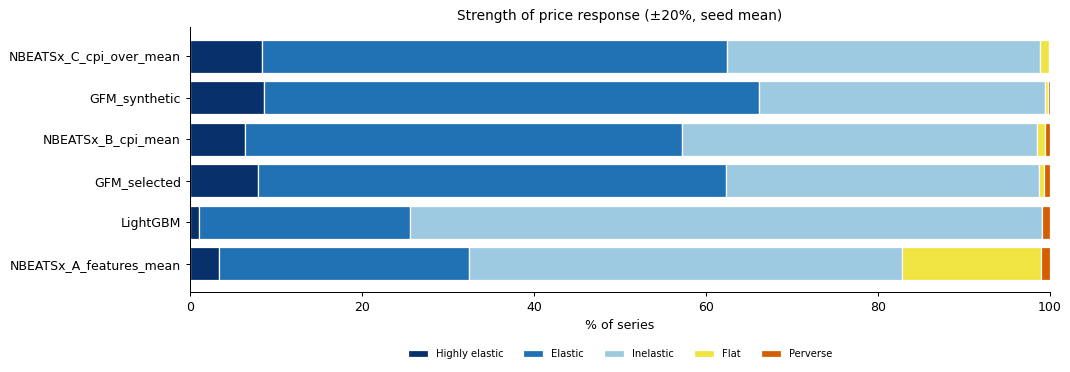

In [12]:
if strength:
    gplt.plot_elasticity_strength(strength,
                                  title="Strength of price response (±20%, seed mean)")
else:
    print("No per-series sweeps saved yet: the reported table above is the response evidence.")

<!-- DRAFT: Graeme to edit -->
### Reading the result

* Compare the GFM's median elasticity (≈ −1.28) with the empirical ≈ −3.6 on this data.
  The research's −0.4 to −0.7 came from a different panel
  [100k set] and is not the target here.
* If LightGBM appears, expect a response that shrinks as the shock grows and goes flat
  outside the prices it has seen: an artefact of tree splits, not of demand (§5).
* Remember the research's sharpest negative result: elasticity tuned on one window did not
  carry to the next (it shrank 7–18×, §6). Treat any one-window response as provisional.

*Exact numbers vary with seed and hardware.*

<!-- DRAFT: Graeme to edit -->
### The final price-response table

The sweep above moves `price_index` alone, over all 14 weeks. A planner asks a different
question: *what happens in a week we run a 20% discount?* So every model that can be asked is
probed the same way (phase 7b, `gp.price_probes` and `gp.promo_calendars`): the price falls
and every input built from it is rebuilt, as in a real discount week.

| Column | What it measures |
|---|---|
| `e20 (sweep)` | sweep's median arc elasticity at ±20%, `price_index` alone (04–05) |
| `cut20 e`, `cut20 lift` | one-week 20% cut, test week 5, inputs rebuilt (the headline) |
| `cut20+promo lift` | the same cut with the promotion flag on as well |
| `right sign` | share of cuts that lift sales, random promotion calendars |
| `lift 10/20/30%` | median lift in the cut week, random calendars, by cut depth |

The GFM rows are 3-seed means (refitted in 05b); Chronos-2 comes from 07, LightGBM from 04.
The last rows are references: the lift the data's own elasticity implies, and the lift 05b
planted in its training copies.

In [13]:
def probe_sources() -> dict:
    """Model -> (fixed probe rows, calendar rows) for every model probed upstream."""
    def table(name):
        path = gd.TABLE_DIR / f"{name}.parquet"
        return pd.read_parquet(path) if path.exists() else None

    sources = {"Chronos2_zs_cov": (table("07_chronos_probe"), table("07_chronos_calendar")),
               "LightGBM": (table("04_lgbm_probe"), table("04_lgbm_calendar"))}
    if (gd.CONFIG_DIR / "05b_synthetic.json").exists():
        runs_by = gd.load_config("05b_synthetic").get("probe_runs", {})
        names = {"05": "GFM_05" if synthetic_won else "GFM_selected",
                 "05b": "GFM_selected" if synthetic_won else "GFM_synthetic"}
        for key, run_name in runs_by.items():
            runs = gd.load_runs(run_name)
            sources[names[key]] = (gp.seed_mean_q([r["probe7b"] for r in runs], gp.PROBE_KEYS),
                                   gp.seed_mean_q([r["calendar"] for r in runs], gp.CAL_KEYS))
    return {m: v for m, v in sources.items() if v[0] is not None and v[1] is not None}


rows = {}
lift_curves = {}
for model, (probe_rows, calendar_rows) in probe_sources().items():
    probes = gp.probe_report(probe_rows)
    calendar = gp.calendar_report(calendar_rows).set_index("depth")
    cut20 = gp.headline(probes)
    promo = gp.headline(probes, mode="pulse_all_promo")
    calendar_resp = gp.probe_response(calendar_rows)
    rows[model] = {"median RMSSE": ratings["median_rmsse"].get(model, np.nan),
                   "e20 (sweep)": response["median_e20"].get(model, np.nan)
                   if "median_e20" in response else np.nan,
                   "cut20 e": cut20["median_elasticity"], "cut20 lift": cut20["median_lift"],
                   "cut20+promo lift": promo["median_lift"],
                   "right sign": float(calendar_resp["right_sign"].mean()),
                   **{f"lift {d:.0%}": calendar["median_lift"].get(d, np.nan)
                      for d in (0.10, 0.20, 0.30)}}
    lift_curves[model] = calendar["median_lift"]

empirical_all = gd.load_config("04_price")["empirical_all"]
depths = list(gp.CAL_DEPTHS)
implied = pd.Series(gp.implied_lift(empirical_all, depths), index=depths)
planted = pd.Series(gp.SYNTHETIC_LIFT)
references = {f"implied by the data (e ≈ {empirical_all:.1f})": implied,
              "planted in 05b's copies": planted}
for name, lift in references.items():
    rows[name] = {"cut20 e": gp.arc_one_side(1.0, 1 + lift[0.20], -0.20),
                  "cut20 lift": lift[0.20],
                  **{f"lift {d:.0%}": lift[d] for d in (0.10, 0.20, 0.30)}}
price_table = pd.DataFrame(rows).T
price_table.round(3)

,median RMSSE,e20 (sweep),cut20 e,cut20 lift,cut20+promo lift,right sign,lift 10%,lift 20%,lift 30%
Chronos2_zs_cov,0.512,NaN,-1.433,0.371,0.434,0.896,0.184,0.452,0.752
LightGBM,0.568,-0.661,-1.095,0.277,0.435,0.976,0.102,0.266,0.436
GFM_selected,0.546,-1.275,-1.792,0.491,0.594,0.994,0.262,0.566,0.894
GFM_synthetic,0.543,-1.337,-1.730,0.475,0.585,0.993,0.262,0.555,0.903
implied by the data (e ≈ -3.6),NaN,NaN,-3.465,1.252,NaN,NaN,0.467,1.252,2.660
planted in 05b's copies,NaN,NaN,-2.077,0.600,NaN,NaN,0.350,0.600,1.500


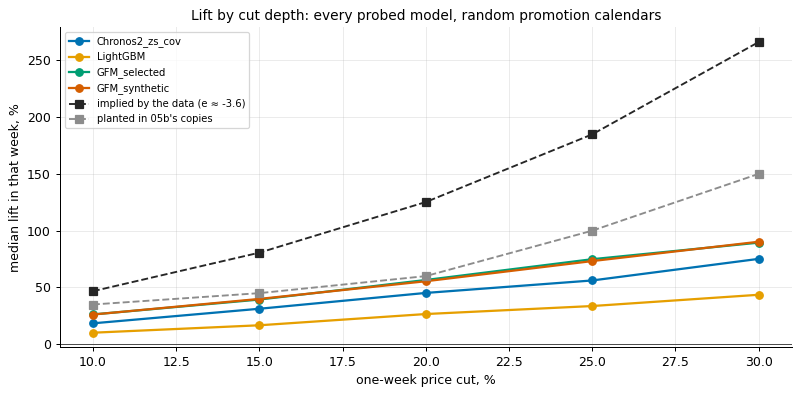

In [14]:
gplt.plot_lift_by_depth(lift_curves, references=references,
                        title="Lift by cut depth: every probed model, random promotion calendars")

<!-- DRAFT: Graeme to edit -->
### Reading the result

* Read `cut20 lift` against the reference rows. How much of the lift the data implies does
  each model forecast for a one-week 20% discount?
* `right sign` near 1 means nearly every cut lifts the forecast. A model can be right-signed
  everywhere and still far too weak: the depth chart shows by how much.
* The most accurate model need not have the most believable response. A model used to plan
  promotions should be good on both.
* On this run, every model is right-signed and every model is too weak. For a one-week 20%
  cut the data implies a lift of ≈ +125%. The GFMs forecast ≈ +48%, Chronos-2 ≈ +37% and
  LightGBM ≈ +28%. 05b's planted lift (+60%) sits between the models and the data.
* The GFMs are the most consistent (≈ 99% of calendar cuts right-signed), then LightGBM
  (≈ 98%), then Chronos-2 (≈ 90%). The most accurate model, Chronos-2, has the weakest and
  least consistent response of the neural models.

*Exact numbers vary with seed and hardware.*

<!-- DRAFT: Graeme to edit -->
## 7. The final model

The rule, fixed before looking: **keep the selected GFM unless another single model beats
its median RMSSE by more than the noise floor.** The GFM's price response was checked in
04–05b; a model that is only tied on accuracy gives no reason to drop that. The rule reads
the test window, but it can only overturn the incumbent on a clear win, so it is a check,
not a fresh search.

In [15]:
singles = ratings.copy()
best_single = singles["median_rmsse"].idxmin()
if selected_col in singles.index and singles.loc[selected_col, "tied_with_best"]:
    final_model = selected_col
else:
    final_model = best_single
print(f"final model: {final_model} (best single model: {best_single})")

final model: Chronos2_zs_cov (best single model: Chronos2_zs_cov)


In [16]:
baseline_names = gd.load_config("00_baselines")["baselines"]
standings = ratings.join(response, how="left")
standings["role"] = "model"
standings.loc[standings.index.isin(baseline_names), "role"] = "baseline"
standings.loc[final_model, "role"] = "final"
standings.round(3)

,median_rmsse,mean_rmsse,avg_win_rate,bradley_terry,elo,tied_with_best,median_e20,share_perverse,share_flat,n_estimable,invariance,role
Chronos2_zs_cov,0.512,1.044,0.640,1101.640,1121.332,True,NaN,NaN,NaN,NaN,NaN,final
NHITS_recipe_mean,0.537,1.028,0.612,1080.816,1116.443,False,NaN,NaN,NaN,NaN,NaN,model
NBEATSx_B_cpi_mean,0.540,1.043,0.614,1082.608,1075.119,False,-1.127,0.006,0.012,680.0,1.279,model
GFM_synthetic,0.543,1.738,0.603,1074.063,1099.210,False,-1.337,0.003,0.003,680.0,1.204,model
GFM_selected,0.546,1.037,0.599,1071.279,1073.616,False,-1.275,0.007,0.006,680.0,1.209,model
GFM_cluster_static,0.550,1.055,0.583,1059.571,1063.175,False,NaN,NaN,NaN,NaN,NaN,model
GFM_BottomUp,0.552,1.046,0.590,1065.230,1039.219,False,NaN,NaN,NaN,NaN,NaN,model
NBEATSx_C_cpi_over_mean,0.553,1.042,0.591,1065.363,1076.581,False,-1.253,0.001,0.010,680.0,1.212,model
NBEATSx_A_features_mean,0.568,1.078,0.556,1040.635,1036.636,False,-0.601,0.010,0.165,680.0,1.701,model
NBEATSx_recipe_mean,0.568,1.078,0.556,1040.635,1036.636,False,NaN,NaN,NaN,NaN,NaN,model


<!-- DRAFT: Graeme to edit -->
The class heatmap (F3): median RMSSE by sales class (columns) for the final model, the top
five and the two yardsticks. Greener is better; read down a column to compare models.

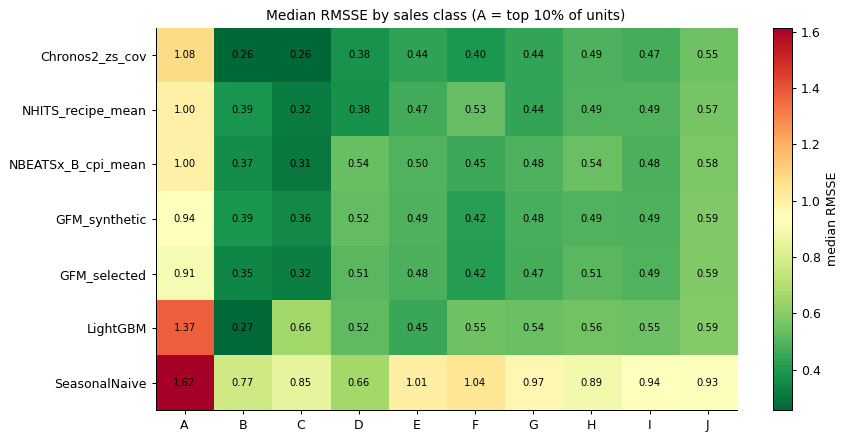

In [17]:
contenders = list(dict.fromkeys([final_model] + list(ratings.index[:5])
                                + ["LightGBM", "SeasonalNaive"]))
contenders = [m for m in contenders if m in R.columns]
gplt.plot_class_heatmap(R, info, models=contenders)

<!-- DRAFT: Graeme to edit -->
### The final model against the yardsticks

First against SeasonalNaive (F4). Bars above 0.5 are classes where the final model wins
more series than it loses; the volume bars weight each series by its sales.

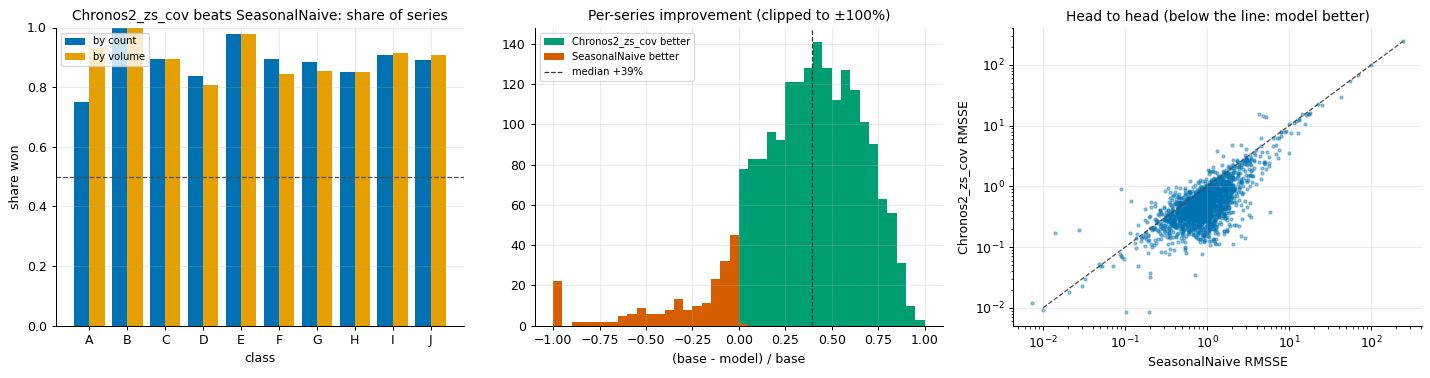

,win_share,win_share_volume,n
sale_class,,,
A,0.750,0.931,4.0
B,1.000,1.000,10.0
C,0.895,0.896,19.0
D,0.839,0.806,31.0
E,0.978,0.979,46.0
F,0.896,0.844,67.0
G,0.885,0.854,96.0
H,0.851,0.850,148.0
I,0.907,0.915,259.0


In [18]:
gplt.plot_wins(R, info, model=final_model, baseline="SeasonalNaive")

<!-- DRAFT: Graeme to edit -->
Then against LightGBM, the strongest Day 1 model (or against the selected GFM, if LightGBM
is the final model).

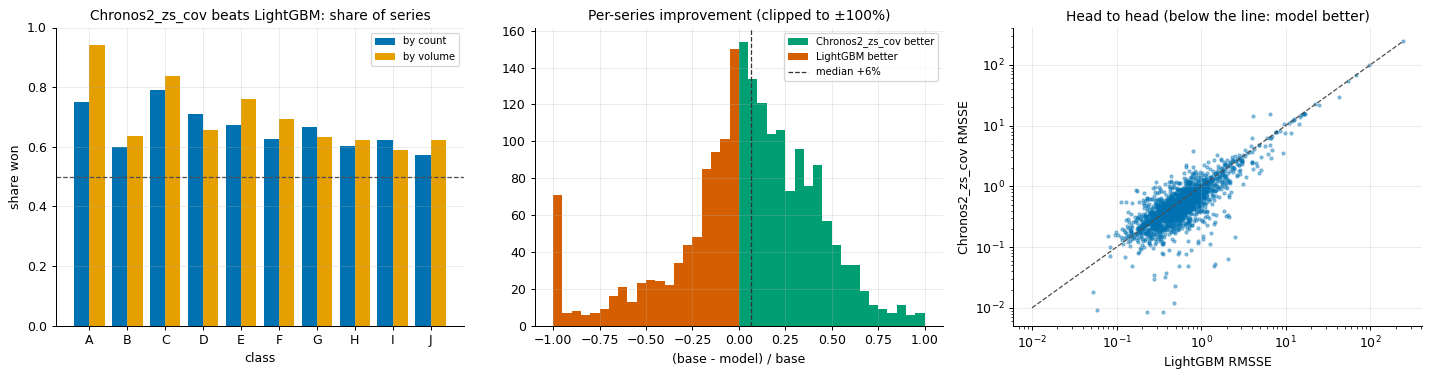

,win_share,win_share_volume,n
sale_class,,,
A,0.750,0.942,4.0
B,0.600,0.636,10.0
C,0.789,0.836,19.0
D,0.710,0.658,31.0
E,0.674,0.759,46.0
F,0.627,0.692,67.0
G,0.667,0.632,96.0
H,0.601,0.621,148.0
I,0.622,0.589,259.0


In [19]:
rival = "LightGBM" if final_model != "LightGBM" else selected_col
gplt.plot_wins(R, info, model=final_model, baseline=rival)

<!-- DRAFT: Graeme to edit -->
## 8. Final standings

One bar per model: median RMSSE on all evaluation series, with the mean as a black dot. The
shaded **equivalence band** runs from the best single model's median to one noise floor
above it: bars that end inside it are tied with the best. Green is the final model, grey the
Day 1 baselines, orange the ensembles. Ensembles are scored on all series here, so they are
flattered (see section 5).

The axis stops at `X_MAX`. A few means run into the hundreds or thousands (NBEATSx off the
shelf, from a handful of exploding series); those dots sit on the right edge as ▶ with their
value written beside them, so the differences between the rest stay visible.

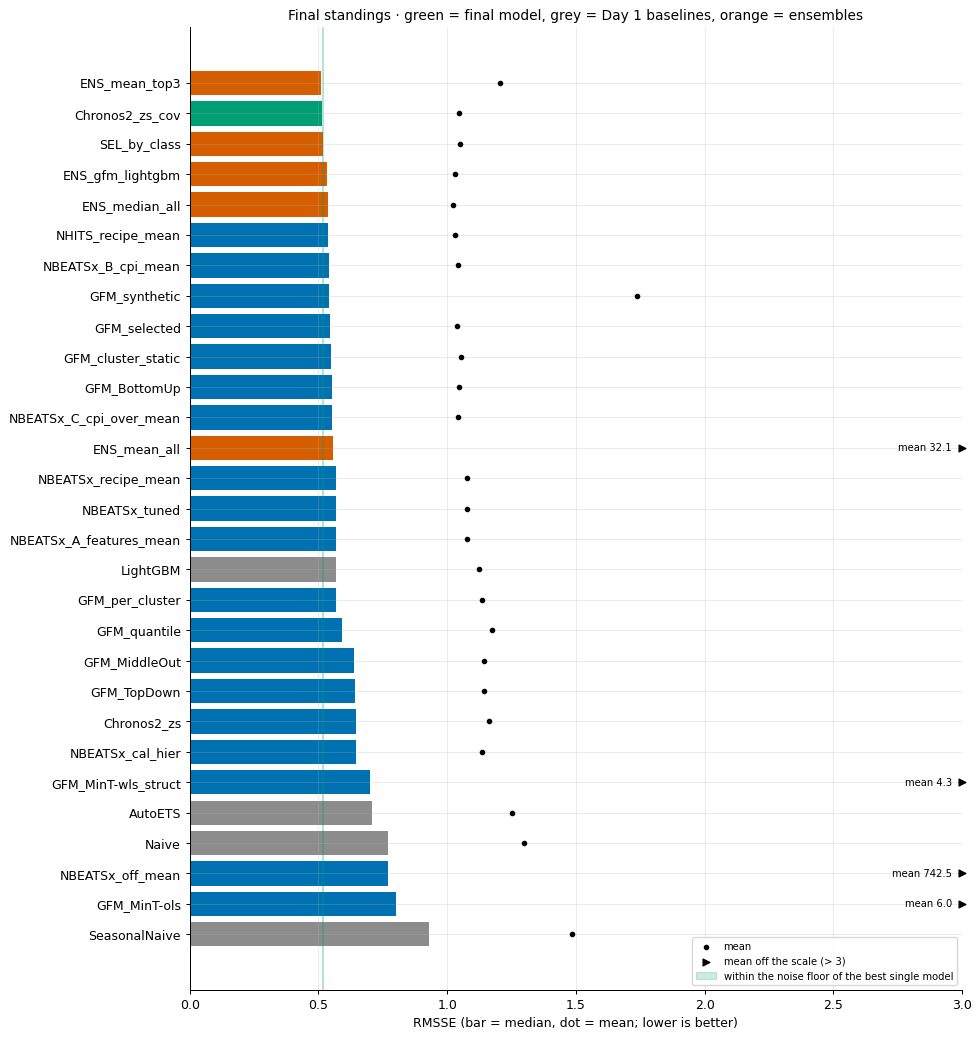

In [20]:
all_scores = gd.per_series(gd.score(fc.merge(ens, on=["unique_id", "ds"]), test, train))
board = pd.DataFrame({"median_rmsse": all_scores.median(), "mean_rmsse": all_scores.mean()})
board = board.sort_values("median_rmsse", ascending=False)
colours = []
for m in board.index:
    if m in ens_models:
        colours.append(gplt.COLOURS["bad"])
    elif m == final_model:
        colours.append(gplt.COLOURS["good"])
    elif m in baseline_names:
        colours.append("0.55")
    else:
        colours.append(gplt.MODEL_COLOURS[0])
fig, ax = plt.subplots(figsize=(11, 0.35 * len(board) + 1.5))
ax.barh(board.index, board["median_rmsse"], color=colours)
X_MAX = 3                   # RMSSE axis limit; means beyond it are marked at the edge
off_scale = board["mean_rmsse"] > X_MAX
on_scale = board[~off_scale]
ax.scatter(on_scale["mean_rmsse"], on_scale.index, color="black", s=12, zorder=3, label="mean")
if off_scale.any():
    ax.scatter(np.full(off_scale.sum(), X_MAX), board.index[off_scale], marker=">",
               color="black", s=30, zorder=3, clip_on=False,
               label=f"mean off the scale (> {X_MAX})")
for m in board.index[off_scale]:
    ax.annotate(f"mean {board.loc[m, 'mean_rmsse']:,.1f}", (X_MAX, m), xytext=(-8, 0),
                textcoords="offset points", ha="right", va="center", fontsize=8)
ax.set_xlim(0, X_MAX)
if noise_floor:
    ax.axvspan(best_median, best_median + noise_floor, color=gplt.COLOURS["band"], alpha=0.2,
               label="within the noise floor of the best single model")
ax.set(xlabel="RMSSE (bar = median, dot = mean; lower is better)",
       title="Final standings · green = final model, grey = Day 1 baselines, "
             "orange = ensembles")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

In [21]:
held_out_table = held_scores.set_index("model")[["median_rmsse", "mean_rmsse"]].round(4)
held_out_table = held_out_table.to_dict("index")
gd.save_config("10_final", {
    "models": models,
    "left_out": left_out.to_dict(),
    "n_series": int(R.shape[0]),
    "noise_floor": noise_floor,
    "final_model": final_model,
    "best_single_model": best_single,
    "final_rule": "selected GFM unless a single model beats its median RMSSE by more than "
                  "the 02 noise floor",
    "standings": standings.round(4).reset_index(names="model").to_dict("records"),
    "tied_with_best": list(ratings.index[ratings["tied_with_best"]]),
    "ensembles": {"top3": top3, "class_choice": class_choice,
                  "selection_half_seed": bc.RANDOM_SEED, "held_out": held_out_table},
    "elasticity_reported": reported.round(4).to_dict("records"),
    "elasticity_from_sweeps": list(strength),
    "price_response": price_table.round(4).reset_index(names="model").to_dict("records"),
})

PosixPath('/home/gdavidson/code/time-series-forecasting-bootcamp/results/day2_full/configs/10_final.json')

<!-- DRAFT: Graeme to edit -->
## Discussion

* Which models are tied with the best? If several are, accuracy alone cannot choose: price
  response, the cost of training and serving, and the seed spread can.
* Does the final model win where the sales are (the volume bars), or only on count?
* Does the GFM + LightGBM average keep the best of both? How would you sweep its price
  response?

### What we learnt on Day 2

* **Training is most of the battle.** Scaled steps, warm-up, clipping and best-weights
  retention took the research from 3 usable runs in 6 to 6 in 6 (§3, [100k set]); 01 tests
  the recipe here. Seed noise then sets the bar: a gap below the 02 noise floor is a tie, not
  a finding [method].
* **Accuracy.** The final model, Chronos-2 zero-shot with the price and promotion covariates,
  reaches a median RMSSE of ≈ 0.512 (mean ≈ 1.04), against ≈ 0.929 for SeasonalNaive and
  ≈ 0.568 for LightGBM on the same evaluation series. The best trained GFM is ≈ 0.537.
* **Price response is a separate test.** An accurate model can ignore price or respond the
  wrong way. In the research the most accurate trials had the weakest elasticity (§6), and
  LightGBM, the most accurate model, had an artefactual response (§5) [100k set]. Here the
  phase 7b probes (a one-week 20% cut with every price input rebuilt) give the selected GFM
  a median elasticity of ≈ −1.79 (lift ≈ +49%) and the final model, Chronos-2, ≈ −1.43
  (≈ +37%), against ≈ −3.5 (≈ +125%) implied by the data. Chronos-2 lifts ≈ 90% of random
  promotion cuts, the GFM ≈ 99%. Every model is right-signed and too weak.
* **Tune on validation, test once.** The research's early tuning was scored on its test
  window (§1). Once it tuned properly, accuracy carried to a new window but elasticity did
  not (§6). So trust accuracy gains across windows more than elasticity gains.
* **New work, not settled practice.** Synthetic discounts (05b), per-cluster models (06),
  GFM-based reconciliation (08) and conformal bands (09) go beyond the research. Read their
  results as leads.
* **Average rather than select.** In the original lab, averaging beat picking a model per
  segment. Here the top-3 average reaches ≈ 0.507 on the held-out half.

**Try it:** change the selection half (`bc.RANDOM_SEED` in the split) and see whether the
top 3 and the per-class choice stay the same.